# **Connect to GEE**

In [ ]:
!pip install -q --upgrade --pre xee
!pip install -q -U geemap

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 49.4 MB/s eta 0:00:00


In [ ]:
import ee

In [ ]:
ee.Authenticate()
ee.Initialize(
    project = 'ee-amirhosseinahrari',
    opt_url = 'https://earthengine-highvolume.googleapis.com'
)

# **Study Area**

In [ ]:
import geemap

In [ ]:
map = geemap.Map(basemap = 'SATELLITE')
map

Map(center=[0, 0], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright', transp…

In [ ]:
roi = map.draw_last_feature.geometry()
roi

ee.Geometry({
  "functionInvocationValue": {
    "functionName": "Feature.geometry",
    "arguments": {
      "feature": {
        "functionInvocationValue": {
          "functionName": "Feature",
          "arguments": {
            "geometry": {
              "functionInvocationValue": {
                "functionName": "GeometryConstructors.Polygon",
                "arguments": {
                  "coordinates": {
                    "constantValue": [
                      [
                        [
                          54.294434,
                          36.934525
                        ],
                        [
                          54.294434,
                          37.072163
                        ],
                        [
                          54.553299,
                          37.072163
                        ],
                        [
                          54.553299,
                          36.934525
                        ],
                        [
                          54.294434,
                          36.934525
                        ]
                      ]
                    ]
                  },
                  "geodesic": {
                    "constantValue": false
                  }
                }
              }
            }
          }
        }
      }
    }
  }
})

# **Landsat Image Collection**

In [ ]:
landsat = (
    ee.ImageCollection("LANDSAT/LC08/C02/T1_L2")
    .filterDate('2018','2020')
    .filterBounds(roi)
)

landsat

In [ ]:
def ndvi(img):
  qa_pixel = img.select('QA_PIXEL')
  bit1 = qa_pixel.bitwiseAnd(1 << 1).neq(0)
  bit2 = qa_pixel.bitwiseAnd(1 << 2).neq(0)
  bit3 = qa_pixel.bitwiseAnd(1 << 3).neq(0)
  bit4 = qa_pixel.bitwiseAnd(1 << 4).neq(0)
  mask = bit1.Or(bit2).Or(bit3).Or(bit4)
  sr = img.select('SR_B.*').multiply(2.75e-05).add(-0.2)
  ndvi = sr.normalizedDifference(['SR_B5','SR_B4']).rename('ndvi')
  return ndvi.updateMask(mask.Not()).copyProperties(img, ['system:time_start'])


In [ ]:
landsat_ndvi = landsat.map(ndvi)

In [ ]:
landsat_ndvi

# **to Xarray**

In [ ]:
from xee import helpers
from shapely.geometry import shape
import xarray as xr

In [ ]:
landsat.first().select('SR_B1').projection().crs()

In [ ]:
grid = helpers.fit_geometry(
    geometry = shape(roi.getInfo()),
    grid_crs = 'EPSG:32640',
    grid_scale = (100, -100)
)

In [ ]:
ds = xr.open_dataset(
    landsat_ndvi,
    engine = 'ee',
    **grid
)

In [ ]:
ds = ds.sortby('time') * 1

# **Temporal Resampling**

In [ ]:
ds_monthly = ds.resample(time = 'ME').mean('time')

In [ ]:
baseline = ds_monthly.max(dim = 'time')
flood = ds_monthly.sel(time = '2019-04').squeeze('time')
diff = baseline - flood

In [ ]:
import matplotlib.pyplot as plt

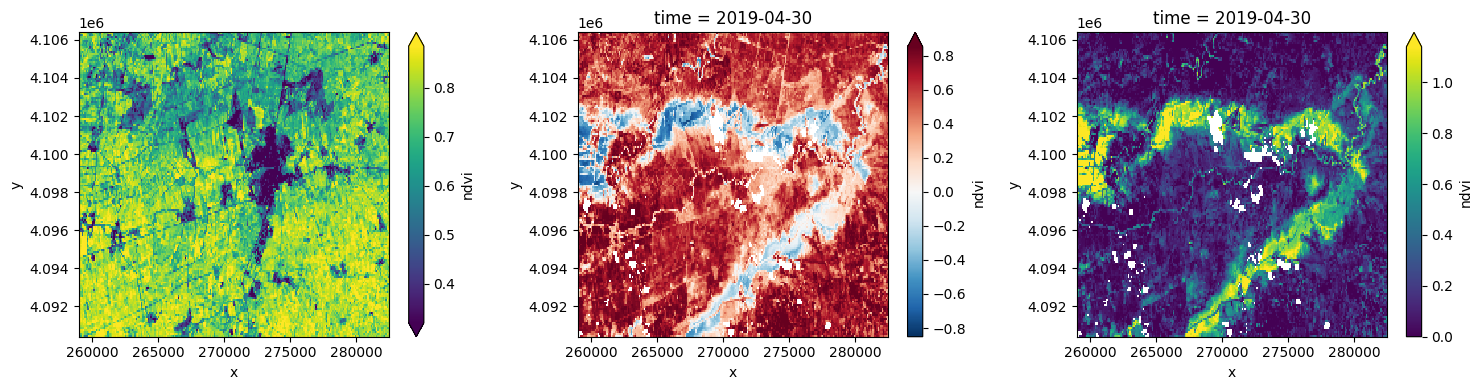

In [ ]:
fig, ax = plt.subplots(1, 3, figsize = (15, 4))

baseline.ndvi.plot(ax = ax[0], robust =True)
flood.ndvi.plot(ax = ax[1], robust = True)
diff.ndvi.plot(ax = ax[2], robust = True)

plt.tight_layout()

In [ ]:
diff_smooth = diff.rolling(
    x = 11,
    y = 11,
    min_periods = 1,
    center = True
).median('time')

diff_fill = diff.fillna(diff_smooth)

In [ ]:
from skimage.segmentation import slic

In [ ]:
help(slic)

In [ ]:
from scipy.ndimage import mean

In [ ]:
segment = slic(
    diff_fill.ndvi.values,
    n_segments = 1000,
    compactness = 0.1,
    sigma = 0.1,
    start_label = 1,
    channel_axis = None
)

flood_segment = mean(
    diff_fill.ndvi.values,
    labels = segment,
    index = segment
)

In [ ]:
flood_segment = xr.DataArray(
    flood_segment,
    dims = diff_fill.dims,
    coords = diff_fill.coords
)

In [ ]:
from skimage.filters import threshold_otsu

In [ ]:
thr = threshold_otsu(flood_segment.values)
thr

np.float64(0.429870054662252)

In [ ]:
flood_mask = (flood_segment >= thr).astype(int)

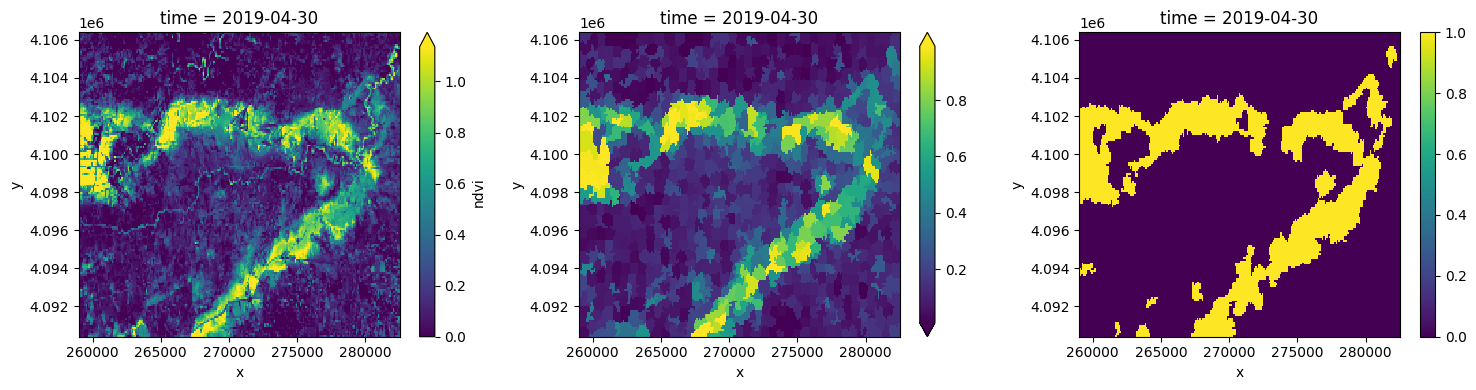

In [ ]:
fig, ax = plt.subplots(1, 3, figsize = (15, 4))

diff_fill.ndvi.plot(ax = ax[0], robust = True)
flood_segment.plot(ax = ax[1], robust = True)
flood_mask.plot(ax = ax[2])

plt.tight_layout()

# **Area**

In [ ]:
import numpy as np

In [ ]:
flood_area = flood_mask.isin(1).sum(dim = ['x','y']).item() * ((100 * 100) / 1e6)
np.round(flood_area, 1)

np.float64(78.1)

In [ ]:
noflood_area = flood_mask.isin(0).sum(dim = ['x','y']).item() * ((100 * 100)/1e6)
noflood_area

297.93

In [ ]:
total_area = flood_area + noflood_area
flood_perc = flood_area / total_area * 100
flood_perc

20.763297872340427